# Phase 1: Baselines
**Project:** *Lead I or Twelve? Measuring How Much Heart-Disease Signal Survives a Wearable-Style Single-Lead ECG*

Logistic regression and gradient-boosted trees on the hand-made ECG features from Checkpoint 1, trained separately for each lead set (A = 12 leads, B = 6 limb leads, C = Lead I only).

**Requires:** `Checkpoint1_PTBXL.ipynb` must have been run once, so that `data/handcrafted_features.parquet` exists. That file is committed to the repo, so on Colab this notebook only downloads the two small label files.

## Preprocessing pipeline: raw ECG to model-ready input

| step | what happens | where |
|---|---|---|
| 1. Raw data | PTB-XL 1.0.3 at 100 Hz: 21,799 recordings, each a 1000 × 12 array (10 s × 12 leads), in mV | `Checkpoint1_PTBXL.ipynb` |
| 2. Labels | The 44 diagnostic SCP statements map to 5 superclasses (NORM, MI, STTC, CD, HYP). Target `abnormal` = carries any of MI/STTC/CD/HYP. The 411 recordings with no diagnostic superclass are dropped → **21,388** | Checkpoint 1; repeated in section 1 below |
| 3. Feature extraction | R-peaks found on Lead I (neurokit2) → 4 rhythm features. A median beat per lead → 6 shape features per lead (R and S amplitude, QRS width, ST level at +80 ms, T amplitude, signal std) | Checkpoint 1, cached to `data/handcrafted_features.parquet` |
| 4. Lead sets | A = all 12 leads (76 features), B = 6 limb leads (40), C = Lead I (10) | section 3 below |
| 5. Split | Patient-level 70 / 15 / 15, stratified, saved to `data/splits.csv` | section 2 below |
| 6. Missing values | When R-peak detection fails, that recording's features are NaN. Logistic regression fills them with the **training** median; the trees handle NaN natively | section 4 below |
| 7. Scaling | `StandardScaler` fit on **train** only, for logistic regression. Trees don't need scaling | section 4 below |
| 8. Encoding | None needed: every input is numeric and the targets are already 0/1 | |

**What changed since Checkpoint 1:** the split. Checkpoint 1 used PTB-XL's official folds (1–8 train, 9 validation, 10 test). We moved to our own patient-level 70 / 15 / 15 split so that the validation share is large enough to divide into an eyeball set and a black-box set (explained below). The trade-off: the official folds 9 and 10 had an extra round of label review that our test set doesn't have, which we'll list as a limitation. Everything else (labels, features, lead sets) is unchanged.

## Data split: 70 / 15 / 15

| split | share | used for |
|---|---|---|
| **train** | 70% | fitting the models |
| **eyeball** | 5% | looking at individual errors by hand: which recordings get missed, and why |
| **black box** | 10% | the numbers only: choosing hyperparameters and, in Phase 2, the 95%-specificity cutoff |
| **test** | 15% | final evaluation in Phase 2, used once |

The 15% validation share is divided into an eyeball set and a black-box set, following Andrew Ng's *Machine Learning Yearning*. Once we've looked at individual recordings in the eyeball set, our choices are shaped by them, so its metrics are no longer an unbiased measure. The black-box set is never inspected, so it remains a fair basis for model selection. At 5% (about 1,070 recordings), the eyeball set still contains well over 100 errors to examine.

**Leakage:** 2,111 patients have more than one recording, so the split is made **by patient**: every recording from a patient lands in the same split. It's also stratified on the combination of the 5 diagnostic categories, so each split has roughly the same mix. The split is saved to `data/splits.csv`, and every later notebook (including the CNN) must load it from there.

*This changes the proposal, which planned to use the dataset's folds 1–8 / 9 / 10. One thing to mention on the slides: folds 9 and 10 had an extra round of label review, and our new test set no longer has that guarantee.*

In [1]:
# On Colab: clone the repo and work from inside it, so data/, results/ and the .py modules are where the notebooks expect them.
# Locally this cell does nothing.
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("common.py"):
    REPO = "/content/DeepLearningProject"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/HudsonPifer1217/DeepLearningProject.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb", "neurokit2"], check=True)
print("working directory:", os.getcwd())

working directory: C:\Users\ffjon\CSC-4667\DeepLearningProject


In [2]:
import os, ast, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from common import fetch_ptbxl

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="The least populated class")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_DIR = os.path.join("data", "ptb-xl")
SPLIT_FILE = os.path.join("data", "splits.csv")
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

COL = {"NORM": "#2a78d6", "MI": "#eb6834", "STTC": "#1baf7a", "CD": "#eda100", "HYP": "#e87ba4"}
CFG_COL = {"A_12lead": "#2a78d6", "B_limb": "#1baf7a", "C_leadI": "#eb6834"}
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "axes.titleweight": "bold", "figure.dpi": 110})

## 1. Labels and features
The same label construction as in Checkpoint 1. The baselines only need the cached features, not the raw waveforms.

In [3]:
fetch_ptbxl(["ptbxl_database.csv", "scp_statements.csv"])
db = pd.read_csv(os.path.join(DATA_DIR, "ptbxl_database.csv"), index_col="ecg_id")
db["scp_codes"] = db["scp_codes"].apply(ast.literal_eval)
scp = pd.read_csv(os.path.join(DATA_DIR, "scp_statements.csv"), index_col=0)

SUPER, ABN = ["NORM", "MI", "STTC", "CD", "HYP"], ["MI", "STTC", "CD", "HYP"]
diag_map = scp.loc[scp.diagnostic == 1, "diagnostic_class"].to_dict()
db["super"] = db.scp_codes.apply(lambda codes: {diag_map[c] for c in codes if c in diag_map})
for c in SUPER:
    db[c] = db["super"].apply(lambda s: int(c in s))
db["abnormal"] = (db[ABN].sum(axis=1) > 0).astype(int)
df = db.loc[db[SUPER].sum(axis=1) > 0].copy()

feat_cache = os.path.join("data", "handcrafted_features.parquet")
assert os.path.exists(feat_cache), "Run Checkpoint1_PTBXL.ipynb first to build the feature cache"
F = pd.read_parquet(feat_cache).loc[df.index]
print(f"Recordings: {len(df):,}   features: {F.shape[1]}")

Recordings: 21,388   features: 76


## 2. Patient-level 70 / 15 / 15 split

In [4]:
SPLITS = ["train", "eyeball", "blackbox", "test"]

if os.path.exists(SPLIT_FILE):
    df["split"] = pd.read_csv(SPLIT_FILE, index_col="ecg_id").loc[df.index, "split"]
    print("Loaded existing split from", SPLIT_FILE)
else:
    # 20 patient-grouped chunks of ~5% each, stratified on the diagnostic-category combination
    combo = df[SUPER].astype(str).agg("".join, axis=1)
    sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
    chunk = np.empty(len(df), dtype=int)
    for k, (_, idx) in enumerate(sgkf.split(df, combo, groups=df.patient_id)):
        chunk[idx] = k
    df["split"] = np.select([chunk < 14, chunk == 14, chunk < 17], ["train", "eyeball", "blackbox"], "test")
    df[["patient_id", "split"]].to_csv(SPLIT_FILE)
    print("Created and saved split to", SPLIT_FILE)

pats = df.groupby("split").patient_id.apply(set)
for i, a in enumerate(SPLITS):
    for b in SPLITS[i + 1:]:
        assert not pats[a] & pats[b], f"patient overlap between {a} and {b}"
print("✓ No patient appears in more than one split.")

summary = df.groupby("split").agg(recordings=("abnormal", "size"), patients=("patient_id", "nunique"),
                                  abnormal=("abnormal", "mean"), **{c: (c, "mean") for c in ABN}).reindex(SPLITS)
summary.insert(1, "share", summary.recordings / len(df))
summary.style.format({"recordings": "{:,}", "patients": "{:,}", "share": "{:.1%}", "abnormal": "{:.1%}",
                      **{c: "{:.1%}" for c in ABN}})

Loaded existing split from data\splits.csv
✓ No patient appears in more than one split.


,recordings,share,patients,abnormal,MI,STTC,CD,HYP
split,,,,,,,,
train,"14,974",70.0%,"13,036",57.6%,25.6%,24.5%,22.9%,12.4%
eyeball,"1,069",5.0%,929,57.5%,25.6%,24.3%,22.8%,12.3%
blackbox,"2,138",10.0%,"1,861",57.6%,25.5%,24.4%,23.0%,12.3%
test,"3,207",15.0%,"2,791",57.6%,25.5%,24.5%,22.9%,12.3%


## 3. Feature sets per lead configuration
The 4 rhythm features come from Lead I, so every configuration gets them. The 6 shape features per lead are included only for the leads in that configuration.

In [5]:
LEADS = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]
LEAD_SETS = {"A_12lead": LEADS, "B_limb": LEADS[:6], "C_leadI": ["I"]}
MORPH = ["r_amp", "s_amp", "qrs_width_ms", "st80", "t_amp", "sig_std"]
RHYTHM = ["hr_bpm", "rr_sdnn_ms", "rr_rmssd_ms", "n_beats"]

def baseline_features(cfg):
    return RHYTHM + [f"{l}_{m}" for l in LEAD_SETS[cfg] for m in MORPH]

for cfg in LEAD_SETS:
    assert set(baseline_features(cfg)) <= set(F.columns), cfg
y = df.abnormal.values
mask = {s: (df.split == s).values for s in SPLITS}
pd.Series({cfg: len(baseline_features(cfg)) for cfg in LEAD_SETS}, name="n_features").to_frame()

,n_features
A_12lead,76
B_limb,40
C_leadI,10


### Final model input
One input sample is **one 10-second recording**, summarized as the 4 rhythm features from Lead I plus 6 shape features for each lead in the configuration. `y` is 1 if the recording carries any abnormal category (MI, STTC, CD or HYP) and 0 if it is NORM only. The rows of `X` are the same recordings in every configuration; only the columns change.

In [6]:
shapes = pd.DataFrame({cfg: {f"X_{s}": F[baseline_features(cfg)].values[mask[s]].shape for s in SPLITS}
                       for cfg in LEAD_SETS}).T
shapes.loc["y"] = [y[mask[s]].shape for s in SPLITS]
print(f"Recordings with missing features (R-peak detection failed): {int(F.hr_bpm.isna().sum())}")
shapes

Recordings with missing features (R-peak detection failed): 2


,X_train,X_eyeball,X_blackbox,X_test
A_12lead,"(14974, 76)","(1069, 76)","(2138, 76)","(3207, 76)"
B_limb,"(14974, 40)","(1069, 40)","(2138, 40)","(3207, 40)"
C_leadI,"(14974, 10)","(1069, 10)","(2138, 10)","(3207, 10)"
y,"(14974,)","(1069,)","(2138,)","(3207,)"


## 4. Models and hyperparameter search (black-box set only)

* **Logistic regression:** fill missing values with the training median, then standardize, then logistic regression with balanced class weights. Tuned over the regularization strength `C`.
* **Gradient-boosted trees** (`HistGradientBoostingClassifier`): handles missing values natively, so there's no imputation or scaling step. Tuned over learning rate and tree depth. Its early stopping holds out part of the **train** split internally, so the black-box set is never used for that.

Every candidate is fit on **train** and scored by AUROC on the **black-box** set. The test set isn't used for any decision in this notebook.

In [7]:
MODELS = {
    "logreg": (lambda **p: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=2000, **p)),
               [{"C": c} for c in [0.001, 0.01, 0.1, 1, 10]]),
    "gbt": (lambda **p: HistGradientBoostingClassifier(class_weight="balanced", max_iter=500,
                                                       random_state=SEED, **p),
            [{"learning_rate": lr, "max_depth": d} for lr in [0.05, 0.1] for d in [3, 6, None]]),
}

search, best = [], {}
for cfg in LEAD_SETS:
    Xc = F[baseline_features(cfg)].values
    for name, (make, grid) in MODELS.items():
        for params in grid:
            m = make(**params).fit(Xc[mask["train"]], y[mask["train"]])
            auc = roc_auc_score(y[mask["blackbox"]], m.predict_proba(Xc[mask["blackbox"]])[:, 1])
            search.append({"config": cfg, "model": name, "params": json.dumps(params), "blackbox_auroc": auc})
            if (cfg, name) not in best or auc > best[cfg, name]["auroc"]:
                best[cfg, name] = {"model": m, "params": params, "auroc": auc}

search = pd.DataFrame(search)
search.pivot_table(index=["model", "params"], columns="config", values="blackbox_auroc", sort=False).round(4)

C:\Users\ffjon\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ffjon\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ffjon\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ffjon\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

config                                             A_12lead  B_limb  C_leadI
model  params                                                               
logreg {"C": 0.001}                                  0.8804  0.8684   0.8065
       {"C": 0.01}                                   0.8849  0.8725   0.8115
       {"C": 0.1}                                    0.8860  0.8735   0.8125
       {"C": 1}                                      0.8860  0.8734   0.8127
       {"C": 10}                                     0.8859  0.8734   0.8128
gbt    {"learning_rate": 0.05, "max_depth": 3}       0.9260  0.9046   0.8459
       {"learning_rate": 0.05, "max_depth": 6}       0.9260  0.9031   0.8434
       {"learning_rate": 0.05, "max_depth": null}    0.9267  0.9027   0.8432
       {"learning_rate": 0.1, "max_depth": 3}        0.9244  0.9042   0.8457
       {"learning_rate": 0.1, "max_depth": 6}        0.9253  0.9023   0.8413
       {"learning_rate": 0.1, "max_depth": null}     0.9248  0.9016   0.8429

## 5. Save predictions
The best model for each (lead set, model) pair predicts every recording. Phase 2's `evaluate.py` reads these files. The test predictions are saved now but **not looked at until Phase 2**.

In [8]:
probs = {}
for (cfg, name), b in best.items():
    p = b["model"].predict_proba(F[baseline_features(cfg)].values)[:, 1]
    probs[cfg, name] = p
    np.savez(os.path.join(RESULTS_DIR, f"baseline_{name}_{cfg}.npz"), ecg_id=df.index.values,
             split=df.split.values.astype(str), y=y, p=p, params=json.dumps(b["params"]))
with open(os.path.join(RESULTS_DIR, "baseline_best_params.json"), "w") as fh:
    json.dump({f"{name}_{cfg}": b["params"] for (cfg, name), b in best.items()}, fh, indent=2)
print("Saved:", sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith("baseline_")))

Saved: ['baseline_best_params.json', 'baseline_gbt_A_12lead.npz', 'baseline_gbt_B_limb.npz', 'baseline_gbt_C_leadI.npz', 'baseline_logreg_A_12lead.npz', 'baseline_logreg_B_limb.npz', 'baseline_logreg_C_leadI.npz']


## 6. Results on the black-box set
This is the "done when" table for Phase 1: models × lead sets.

In [9]:
bb = mask["blackbox"]
res = pd.DataFrame([{"model": name, "config": cfg, "params": json.dumps(best[cfg, name]["params"]),
                     "AUROC": roc_auc_score(y[bb], probs[cfg, name][bb]),
                     "AUPRC": average_precision_score(y[bb], probs[cfg, name][bb])}
                    for (cfg, name) in best])
display(res.pivot(index="model", columns="config", values=["AUROC", "AUPRC"]).round(3))
res.set_index(["model", "config"])[["params"]]

AUROC                   AUPRC               
config A_12lead B_limb C_leadI A_12lead B_limb C_leadI
model                                                 
gbt       0.927  0.905   0.846    0.952  0.936   0.899
logreg    0.886  0.873   0.813    0.924  0.914   0.873

,,params
model,config,
logreg,A_12lead,"{""C"": 0.1}"
gbt,A_12lead,"{""learning_rate"": 0.05, ""max_depth"": null}"
logreg,B_limb,"{""C"": 0.1}"
gbt,B_limb,"{""learning_rate"": 0.05, ""max_depth"": 3}"
logreg,C_leadI,"{""C"": 10}"
gbt,C_leadI,"{""learning_rate"": 0.05, ""max_depth"": 3}"


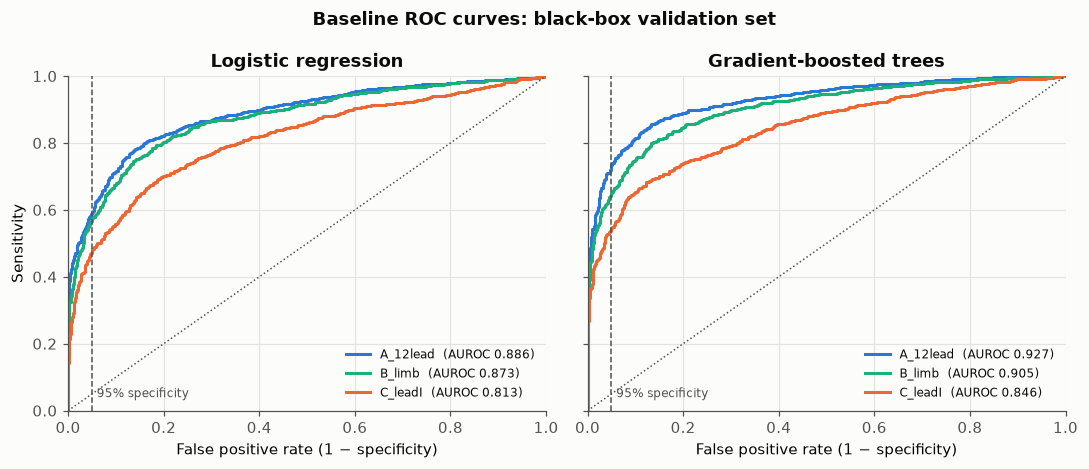

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharey=True)
for ax, name, title in zip(axes, MODELS, ["Logistic regression", "Gradient-boosted trees"]):
    for cfg in LEAD_SETS:
        fpr, tpr, _ = roc_curve(y[bb], probs[cfg, name][bb])
        ax.plot(fpr, tpr, color=CFG_COL[cfg], lw=2,
                label=f"{cfg}  (AUROC {roc_auc_score(y[bb], probs[cfg, name][bb]):.3f})")
    ax.plot([0, 1], [0, 1], color=INK2, lw=1, ls=":")
    ax.axvline(0.05, color=INK2, lw=1, ls="--")
    ax.text(0.06, 0.04, "95% specificity", color=INK2, fontsize=8)
    ax.set(title=title, xlabel="False positive rate (1 − specificity)", xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="lower right", fontsize=8, frameon=False)
axes[0].set_ylabel("Sensitivity")
fig.suptitle("Baseline ROC curves: black-box validation set", fontweight="bold")
plt.tight_layout(); plt.show()

### Overfitting or underfitting?
The same models scored on the recordings they were trained on, next to the unseen black-box set. A large gap means the model has memorized the training set; low scores on both would mean it is underfitting.

In [11]:
tr = mask["train"]
fit = pd.DataFrame([{"model": name, "config": cfg,
                     "train AUROC": roc_auc_score(y[tr], probs[cfg, name][tr]),
                     "black-box AUROC": roc_auc_score(y[bb], probs[cfg, name][bb])} for (cfg, name) in best])
fit["gap"] = fit["train AUROC"] - fit["black-box AUROC"]
fit.set_index(["model", "config"]).round(3)

,,train AUROC,black-box AUROC,gap
model,config,,,
logreg,A_12lead,0.898,0.886,0.012
gbt,A_12lead,0.989,0.927,0.062
logreg,B_limb,0.877,0.873,0.004
gbt,B_limb,0.930,0.905,0.025
logreg,C_leadI,0.824,0.813,0.011
gbt,C_leadI,0.870,0.846,0.025


**Reading the table:**
* **Logistic regression doesn't overfit.** Train and black-box AUROC are within about 0.01 of each other at every lead set. It is the simpler model and is held back by its straight-line decision boundary rather than by memorizing: the trees beat it on unseen data at every lead set.
* **The 12-lead trees overfit somewhat.** They are allowed unlimited depth (the black-box search picked `max_depth=None`), score about 0.99 on train and 0.927 on the black-box set. The black-box score is still the best of any baseline, so the extra flexibility helps more than it hurts, but stronger regularization is worth trying in Checkpoint 3. The depth-3 trees for B and C have a much smaller gap (about 0.025).
* **The Lead-I models score low even on the data they were trained on** (about 0.82–0.87 train AUROC). Their weakness is the input, not overfitting: ten numbers from one lead don't carry enough information. That is the effect the project is measuring.

## 7. Eyeball set: where do the baselines fail?

This is a first look at the hypothesis. A cutoff is chosen on the **black-box** set so that 95% of normal recordings are correctly called normal. That cutoff is then applied to the **eyeball** set, and we check what fraction of each abnormal category gets flagged. This is a preview only: Phase 2 builds the formal version, with confidence intervals, on the test set.

In [12]:
def cutoff_at_specificity(y_true, p, spec=0.95):
    return np.quantile(p[y_true == 0], spec)

ey = mask["eyeball"]
rows = []
for (cfg, name) in best:
    p = probs[cfg, name]
    thr = cutoff_at_specificity(y[bb], p[bb])
    flag = p[ey] >= thr
    row = {"model": name, "config": cfg, "specificity": 1 - flag[y[ey] == 0].mean(),
           "sensitivity": flag[y[ey] == 1].mean()}
    row.update({f"recall_{c}": flag[df[c].values[ey] == 1].mean() for c in ABN})
    rows.append(row)
eyeball = pd.DataFrame(rows).set_index(["model", "config"])
eyeball.style.format("{:.1%}")

,,specificity,sensitivity,recall_MI,recall_STTC,recall_CD,recall_HYP
model,config,,,,,,
logreg,A_12lead,96.5%,61.5%,66.8%,68.8%,70.9%,71.8%
gbt,A_12lead,96.3%,74.3%,80.3%,83.8%,75.8%,80.2%
logreg,B_limb,95.8%,59.0%,66.4%,66.5%,66.0%,65.6%
gbt,B_limb,96.9%,67.8%,76.6%,75.0%,72.5%,72.5%
logreg,C_leadI,95.2%,51.9%,55.8%,63.5%,52.0%,64.1%
gbt,C_leadI,94.5%,57.9%,59.5%,71.2%,58.6%,69.5%


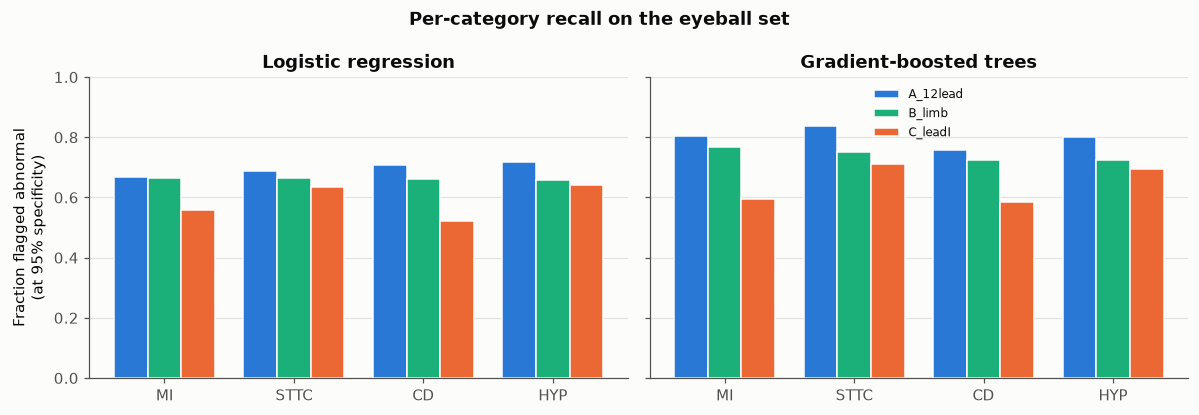

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
x = np.arange(len(ABN)); w = 0.26
for ax, name, title in zip(axes, MODELS, ["Logistic regression", "Gradient-boosted trees"]):
    for j, cfg in enumerate(LEAD_SETS):
        vals = [eyeball.loc[(name, cfg), f"recall_{c}"] for c in ABN]
        ax.bar(x + (j - 1) * w, vals, w, color=CFG_COL[cfg], label=cfg, edgecolor=SURF)
    ax.set_xticks(x, ABN); ax.set_ylim(0, 1); ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Fraction flagged abnormal\n(at 95% specificity)")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Per-category recall on the eyeball set", fontweight="bold")
plt.tight_layout(); plt.show()

### An example error
An MI recording from the eyeball set that the 12-lead tree model flags but the Lead-I tree model misses. The plot shows Lead I (blue, all a wrist device records) next to the other leads (orange) that the 12-lead model has access to. Where an MI shows up depends on where it is: an **inferior** MI (code `IMI`) appears in leads II, III and aVF, which are limb leads. An **anterior** MI (`AMI`, `ASMI`) appears in the chest leads V1–V4.

Eyeball MI recordings caught with 12 leads but missed with Lead I: 62


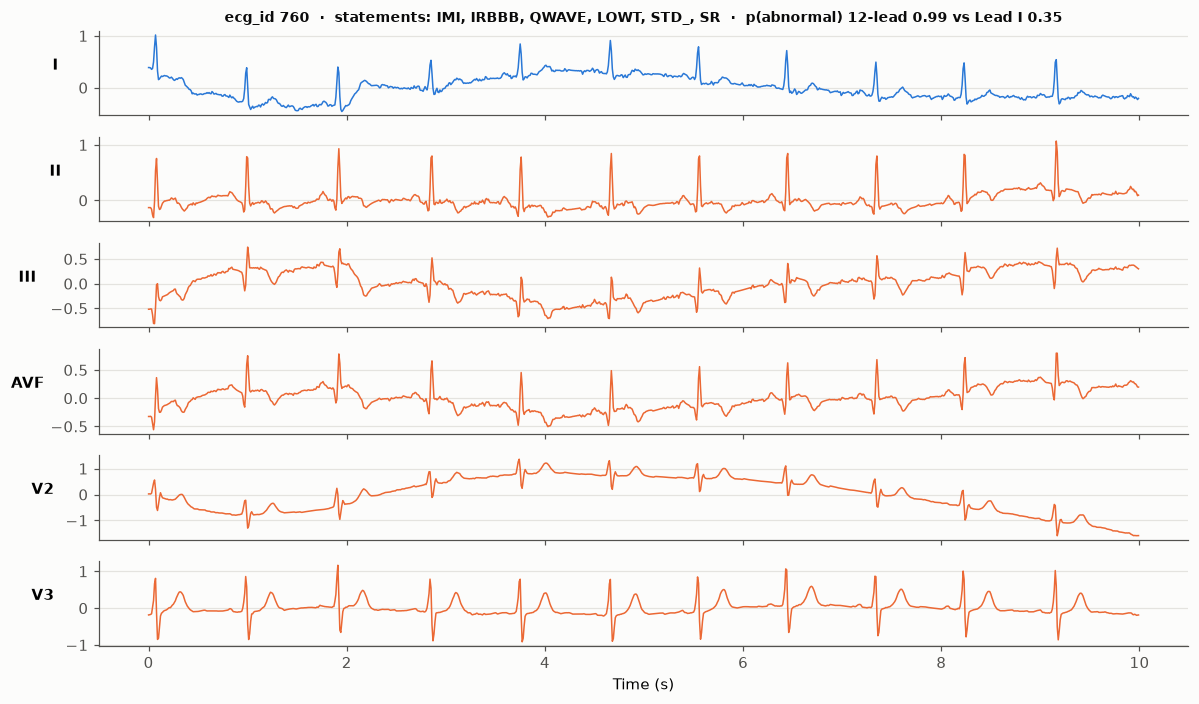

In [14]:
thr_A = cutoff_at_specificity(y[bb], probs["A_12lead", "gbt"][bb])
thr_C = cutoff_at_specificity(y[bb], probs["C_leadI", "gbt"][bb])
cand = df.index[ey & (df.MI.values == 1) & (probs["A_12lead", "gbt"] >= thr_A) & (probs["C_leadI", "gbt"] < thr_C)]
print(f"Eyeball MI recordings caught with 12 leads but missed with Lead I: {len(cand)}")

if len(cand):
    eid = cand[0]
    fetch_ptbxl([df.loc[eid, "filename_lr"] + ext for ext in (".hea", ".dat")])
    sig, meta = wfdb.rdsamp(os.path.join(DATA_DIR, df.loc[eid, "filename_lr"]))
    show = ["I", "II", "III", "AVF", "V2", "V3"]
    t = np.arange(sig.shape[0]) / meta["fs"]
    fig, axes = plt.subplots(len(show), 1, figsize=(11, 6.5), sharex=True)
    for ax, lead in zip(axes, show):
        ax.plot(t, sig[:, LEADS.index(lead)], color=COL["NORM"] if lead == "I" else COL["MI"], lw=1)
        ax.set_ylabel(lead, rotation=0, labelpad=15, fontweight="bold"); ax.grid(axis="x", visible=False)
    axes[-1].set_xlabel("Time (s)")
    codes = ", ".join(df.loc[eid, "scp_codes"])
    axes[0].set_title(f"ecg_id {eid}  ·  statements: {codes}  ·  "
                      f"p(abnormal) 12-lead {probs['A_12lead', 'gbt'][df.index.get_loc(eid)]:.2f} vs "
                      f"Lead I {probs['C_leadI', 'gbt'][df.index.get_loc(eid)]:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

## 8. What we observed

**Black-box AUROC (models × lead sets):**

| | A, 12 leads | B, limb leads | C, Lead I |
|---|---|---|---|
| Logistic regression | 0.886 | 0.873 | 0.813 |
| Gradient-boosted trees | **0.927** | 0.904 | 0.845 |

* **Removing leads costs performance with both models.** Going from 12 leads to Lead I drops AUROC by about 0.07–0.08. Going from 12 to 6 limb leads costs much less (0.01–0.02), so most of the loss happens in the step from limb leads to Lead I alone.
* **The trees beat logistic regression at every lead set** (by about 0.03–0.04 AUROC). So a non-linear model gets more out of the same features, and **0.927 is the number the CNN has to beat** for config A.
* **Tuning barely matters.** Within each model, every setting tried lands within about 0.005 AUROC of the others. These results come from the features, not from lucky hyperparameters.
* **Per-category preview (trees, eyeball set, at 95% specificity):** from 12 leads to Lead I, recall drops about 22 points for MI, 18 for CD, 13 for STTC and 12 for HYP. That **only partly matches the hypothesis**: MI loses the most, as predicted, but CD also loses a lot and HYP loses the least.
* **Caveats before reading too much into that:**
  * The eyeball set is small (about 130 HYP recordings, 275 MI), so each recall number has an uncertainty of roughly ±5–8 points.
  * These are hand-made features. The 4 rhythm features always come from Lead I, so configuration C still sees all of the timing information.
  * Phase 2 (test set, confidence intervals) and the CNN make the real comparison.
* **MI type matters.** The example error is an *inferior* MI, which shows in limb leads II, III and aVF, not the chest leads. If anterior and inferior MI behave differently at configs B and C, that refines the hypothesis and is worth a slide.